# Бенчмарк моделей CLIP / SigLIP2 для локального поиска по галерее

Какая модель лучше всего подходит для поиска **по смыслу** в нашей галерее: запрос на русском или английском → ближайшие картинки.

Данные: **Crossmodal-3600** (3600 фото, подписи людей на 36 языках). Берём случайные 1000 картинок и подписи на `ru` и `en`; каждая подпись — это поисковый запрос, правильный ответ — картинка, которую она описывает.

Что измеряем для каждой модели (каждая в отдельном процессе, чтобы память не смешивалась):

| Группа | Метрики |
|---|---|
| Качество | Recall@1/5/10, NDCG@10, MRR — по всем запросам и отдельно для `ru` и `en` |
| Индексация | время на одну картинку: подготовка (чтение, ресайз) + прогон модели |
| Поиск | задержка одного текстового запроса (батч = 1, как делает API) |
| Ресурсы | RAM под модель, пиковая RAM, сколько ядер CPU занято, число параметров |

Код измерений — в `src/bench/clip_bench.py`, загрузка данных — в `src/bench/data.py`. Результаты по каждой модели кэшируются в `results/<устройство>/raw/*.json`, поэтому ноутбук можно перезапускать без повторных замеров.

## 1. Настройки

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bench.clip_bench import DEFAULT_MODELS, run_all

DEVICE = "cpu"             # "cuda", если установлен torch с CUDA
N_IMAGES = 1000            # размер «галереи»; чем больше, тем строже Recall@K
LANGS = ("en", "ru")
MODELS = DEFAULT_MODELS
PRODUCTION_MODEL = "ViT-B-16-SigLIP2"   # CLIP_MODEL_NAME=hf-hub:timm/ViT-B-16-SigLIP2 в backend/.env.example
FORCE = False              # True — пересчитать, игнорируя кэш

OUT = Path("results") / DEVICE
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## 2. Запуск замеров

При первом запуске скачиваются датасет (~330 МБ) и веса моделей (несколько ГБ, кэш Hugging Face). На CPU полный прогон занимает порядка получаса.

In [2]:
results = run_all(MODELS, OUT, n_images=N_IMAGES, langs=LANGS, device=DEVICE, force=FORCE)
print(f"\nГотово: {len(results)} моделей")

[xlm-roberta-base-ViT-B-32] cached, skipping (force=True to rerun)
[ViT-B-16-SigLIP2] cached, skipping (force=True to rerun)
[ViT-B-32-SigLIP2-256] cached, skipping (force=True to rerun)
[ViT-SO400M-16-SigLIP2-384] cached, skipping (force=True to rerun)
[nllb-clip-base-siglip] cached, skipping (force=True to rerun)

Готово: 5 моделей


## 3. Сводная таблица

In [3]:
df = pd.DataFrame(results)
df = df[df["model"].isin(MODELS)]
for lang in LANGS:
    df[f"R@1 {lang}"] = df["per_lang"].apply(lambda d: d[lang]["Recall@1"])
df = df.sort_values("Recall@1", ascending=False).reset_index(drop=True)

summary = df[[
    "model", "params_m", "Recall@1", "Recall@5", "Recall@10", "NDCG@10",
    "R@1 en", "R@1 ru", "img_total_ms", "query_ms_median", "model_ram_mib", "img_peak_rss_mib",
    "img_cpu_cores_busy",
]].rename(columns={
    "params_m": "Параметры, млн", "img_total_ms": "Картинка, мс", "query_ms_median": "Запрос, мс",
    "model_ram_mib": "RAM сразу после загрузки, МиБ (с буферами загрузки)", "img_peak_rss_mib": "Пик RAM при работе, МиБ",
    "img_cpu_cores_busy": "Ядер CPU",
})
chance = 1 / df["n_images"].iloc[0]
print(f"Галерея: {df['n_images'].iloc[0]} картинок, {df['n_captions'].iloc[0]} запросов ({', '.join(LANGS)}). "
      f"Случайное угадывание: Recall@1 = {chance:.3f}, Recall@10 = {10 * chance:.2f}.")
env = df["env"].iloc[0]
print(f"Железо: {env['cpu_count']} физ. ядер, {env['ram_gib']} ГиБ RAM, torch {env['torch']}, потоков {env['torch_threads']}, устройство: {DEVICE}")
summary.round(3)

Галерея: 1000 картинок, 4000 запросов (en, ru). Случайное угадывание: Recall@1 = 0.001, Recall@10 = 0.01.
Железо: 6 физ. ядер, 31.3 ГиБ RAM, torch 2.15.0+cpu, потоков 6, устройство: cpu


,model,"Параметры, млн",Recall@1,Recall@5,Recall@10,NDCG@10,R@1 en,R@1 ru,"Картинка, мс","Запрос, мс","RAM сразу после загрузки, МиБ (с буферами загрузки)","Пик RAM при работе, МиБ",Ядер CPU
0,ViT-SO400M-16-SigLIP2-384,1136.0,0.791,0.948,0.974,0.887,0.726,0.856,2081.124,313.236,4473,5410.488,5.874
1,ViT-B-16-SigLIP2,375.2,0.767,0.941,0.972,0.876,0.720,0.813,253.381,114.446,1536,2205.285,5.889
2,ViT-B-32-SigLIP2-256,376.9,0.750,0.930,0.968,0.863,0.704,0.796,50.579,62.388,1561,2183.461,5.934
3,xlm-roberta-base-ViT-B-32,366.1,0.718,0.918,0.954,0.841,0.657,0.778,81.179,132.770,3068,3647.641,5.932
4,nllb-clip-base-siglip,507.5,0.709,0.909,0.955,0.834,0.646,0.772,479.201,152.113,4751,2900.297,5.879


In [4]:
# Одинаковые цвета для моделей на всех графиках; модель из приложения подписана звёздочкой.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
color = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(MODELS)}
label = {m: ("★ " + m if m == PRODUCTION_MODEL else m) for m in MODELS}
wrap = lambda m: label[m].replace("-", "-\n", 1)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "font.size": 10})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

## 4. Качество поиска

Слева — доля запросов, для которых правильная картинка попала в топ-K. Справа — Recall@1 отдельно для русских и английских запросов: для нас важно, чтобы русский не отставал.

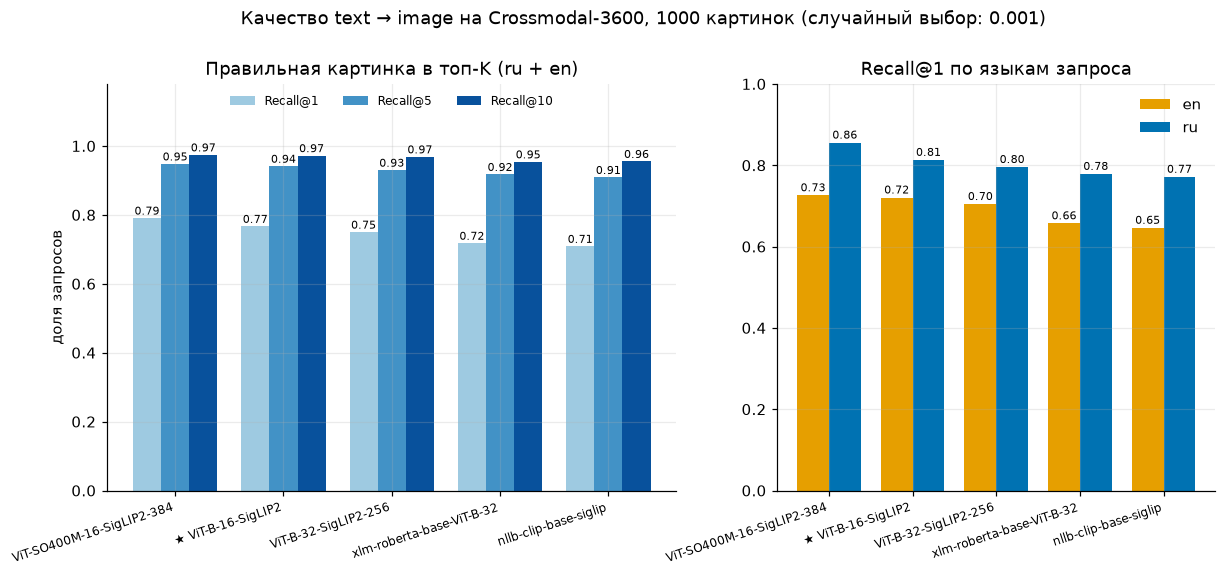

In [5]:
order = list(df["model"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

w = 0.26
for j, k in enumerate(["Recall@1", "Recall@5", "Recall@10"]):
    vals = df[k].values
    bars = a1.bar(np.arange(len(order)) + (j - 1) * w, vals, w, label=k,
                  color=["#9ecae1", "#4292c6", "#08519c"][j])
    for b, v in zip(bars, vals):
        a1.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
a1.set_xticks(range(len(order)), [label[m] for m in order], fontsize=8, rotation=18, ha="right")
a1.set_ylim(0, 1.18); a1.set_ylabel("доля запросов"); a1.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
a1.set_title("Правильная картинка в топ-K (ru + en)")

x = np.arange(len(order)); w = 0.38
for j, lang in enumerate(LANGS):
    vals = df[f"R@1 {lang}"].values
    bars = a2.bar(x + (j - 0.5) * w, vals, w, label=lang, color=["#E69F00", "#0072B2"][j])
    for b, v in zip(bars, vals):
        a2.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
a2.set_xticks(x, [label[m] for m in order], fontsize=8, rotation=18, ha="right")
a2.set_ylim(0, 1.0); a2.legend(frameon=False); a2.set_title("Recall@1 по языкам запроса")
fig.suptitle(f"Качество text → image на Crossmodal-3600, {df['n_images'].iloc[0]} картинок (случайный выбор: {chance:.3f})", y=1.02)
save(fig, "quality")

## 5. Цена качества

Сколько стоит каждая модель в ресурсах: индексация одной картинки, один поисковый запрос и память. Шкала логарифмическая — модели отличаются на порядок.

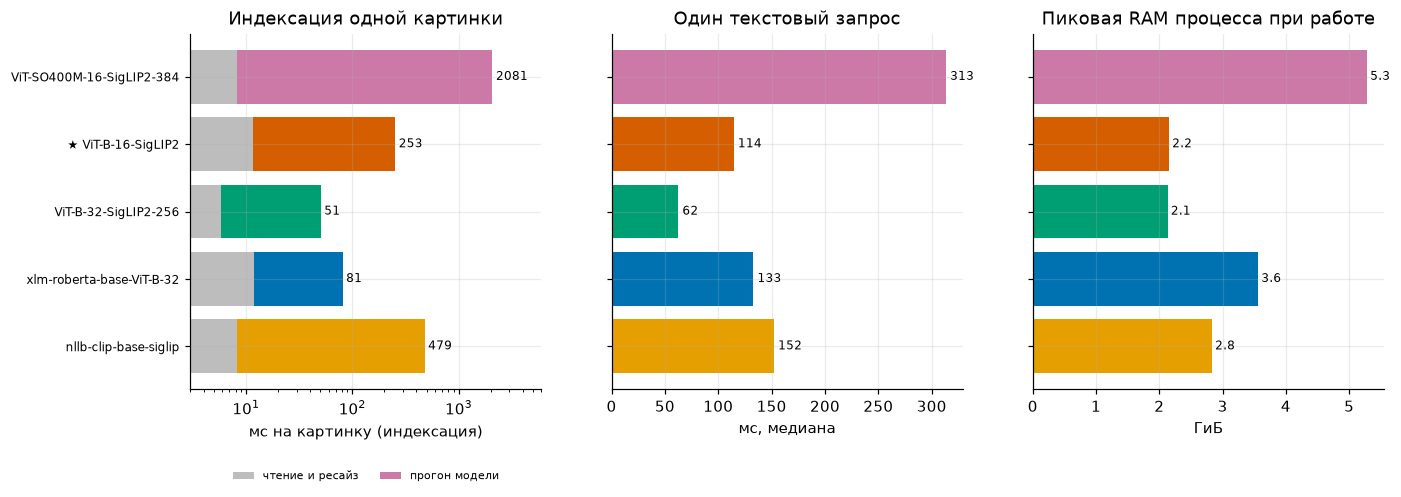

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
d = df.set_index("model").loc[order]
y = np.arange(len(order))[::-1]
names = [label[m] for m in order]
cols = [color[m] for m in order]

ax = axes[0]
ax.barh(y, d["img_preprocess_ms"], color="#bdbdbd", label="чтение и ресайз")
ax.barh(y, d["img_forward_ms"], left=d["img_preprocess_ms"], color=cols, label="прогон модели")
ax.set_xscale("log"); ax.set_xlim(3, 6000); ax.set_yticks(y, names, fontsize=8); ax.set_xlabel("мс на картинку (индексация)")
for yy, v in zip(y, d["img_total_ms"]): ax.text(v * 1.08, yy, f"{v:.0f}", va="center", fontsize=8)
ax.set_title("Индексация одной картинки"); ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

ax = axes[1]
ax.barh(y, d["query_ms_median"], color=cols)
ax.set_yticks(y, [""] * len(y)); ax.set_xlabel("мс, медиана")
for yy, v in zip(y, d["query_ms_median"]): ax.text(v + 4, yy, f"{v:.0f}", va="center", fontsize=8)
ax.set_title("Один текстовый запрос")

ax = axes[2]
ax.barh(y, d["img_peak_rss_mib"] / 1024, color=cols)
ax.set_yticks(y, [""] * len(y)); ax.set_xlabel("ГиБ")
for yy, v in zip(y, d["img_peak_rss_mib"] / 1024): ax.text(v + 0.05, yy, f"{v:.1f}", va="center", fontsize=8)
ax.set_title("Пиковая RAM процесса при работе")
save(fig, "cost")

## 6. Качество против цены

Идеальная модель — в левом верхнем углу: точная и быстрая. Размер пузыря — пиковая RAM.

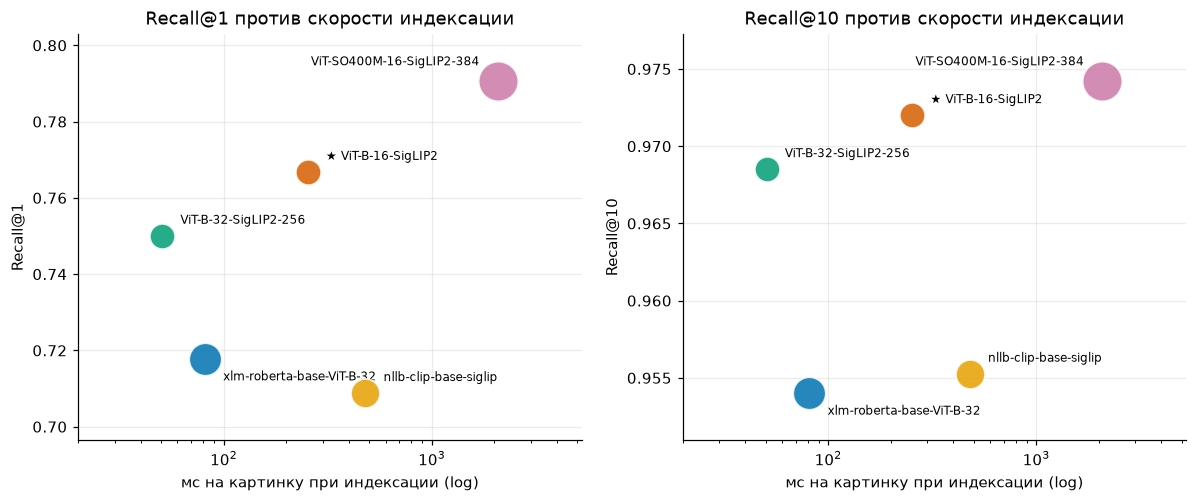

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, metric in zip(axes, ["Recall@1", "Recall@10"]):
    for _, r in df.iterrows():
        ax.scatter(r["img_total_ms"], r[metric], s=r["img_peak_rss_mib"] / 8, color=color[r["model"]],
                   alpha=0.85, edgecolor="white", linewidth=1.2, zorder=3)
        big = r["img_total_ms"] > 1000
        ax.annotate(label[r["model"]], (r["img_total_ms"], r[metric]), textcoords="offset points",
                    xytext=(-12, 10) if big else (12, -14 if r["model"].startswith("xlm") else 8),
                    ha="right" if big else "left", fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel("мс на картинку при индексации (log)"); ax.set_ylabel(metric)
    ax.margins(x=0.25, y=0.15)
axes[0].set_title("Recall@1 против скорости индексации")
axes[1].set_title("Recall@10 против скорости индексации")
save(fig, "tradeoff")

## 7. Выводы

Цифры ниже — из прогона на 1000 картинок и 4000 запросах (ru + en), CPU AMD Ryzen 5 5600H (6 ядер), 31 ГиБ RAM, без GPU. Случайное угадывание дало бы Recall@1 = 0,001.

1. **SigLIP2 заметно лучше остальных семейств.** Все три модели SigLIP2 дают Recall@1 от 0,75 до 0,79, а `xlm-roberta-base-ViT-B-32` — 0,72 и `nllb-clip-base-siglip` — 0,71. При этом `nllb` ещё и в 2 раза медленнее B/16 и занимает больше памяти, а `xlm-roberta` для индексации картинок медленнее B/32-SigLIP2 и занимает в полтора раза больше RAM.
2. **Большая `ViT-SO400M-16-SigLIP2-384` — потолок качества, но не для CPU.** Она лучше B/16 на 2,4 п.п. по Recall@1 (0,791 против 0,767), но индексирует картинку за ~2,1 с против ~0,25 с (в 8 раз дольше) и требует ~5,4 ГиБ RAM против ~2,2 ГиБ. Индексация 1000 фото заняла бы около 35 минут вместо 4. Для локального приложения такая цена не оправдана.
3. **`ViT-B-16-SigLIP2` (в приложении сейчас) — хороший баланс качества.** Recall@1 = 0,767, Recall@10 = 0,972: нужное фото в первой десятке почти всегда. Русские запросы работают не хуже английских (Recall@1 для ru 0,81, для en 0,72).
4. **Запасной вариант, если важна скорость индексации, — `ViT-B-32-SigLIP2-256`.** Она индексирует картинку за ~50 мс (в 5 раз быстрее B/16) и отвечает на запрос за ~62 мс, а теряет всего 1,7 п.п. Recall@1 (0,750) и 0,4 п.п. Recall@10 (0,9685). Если для вас медленная индексация большой галереи — реальная проблема, стоит посмотреть и на неё.

Что учесть:
* Скорость SO400M и `nllb` измерена, пока на ноутбуке параллельно считался OCR-бенчмарк, поэтому их миллисекунды слегка завышены; на выводы это не влияет (разница в разы).
* Скорость измерена в fp32, а приложение запускает модель в `torch.autocast` (на CPU это bfloat16), так что реальные цифры в приложении могут отличаться.
* Метрика считается на галерее из 1000 фото; в большой галерее Recall@K будет ниже у всех моделей, порядок моделей, скорее всего, сохранится.
* Тест на подписях к фотографиям (описание сцены), а не на картинках с текстом: качество OCR-поиска смотрите в `ocr/ocr.ipynb`.

## 8. Сохранение

In [8]:
summary.round(4).to_csv(OUT / "summary.csv", index=False)
print("Сохранено:", OUT / "summary.csv", "и графики в", FIG)

Сохранено: results\cpu\summary.csv и графики в results\cpu\figures
